In [1]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml('mnist_784')

In [2]:
X, y = mnist['data'], mnist['target']
X.shape

(70000, 784)

In [3]:
y.shape

(70000,)

In [4]:
type(X)

pandas.core.frame.DataFrame

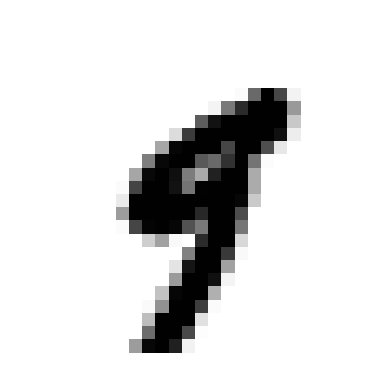

In [5]:
import matplotlib
import matplotlib.pyplot as plt
some_digit = X.iloc[36000]
some_digit_image = some_digit.values.reshape(28,28)
plt.imshow(some_digit_image, cmap=matplotlib.cm.binary,
          interpolation="nearest")
plt.axis("off")
plt.show()

In [6]:
some_digit

pixel1      0
pixel2      0
pixel3      0
pixel4      0
pixel5      0
           ..
pixel780    0
pixel781    0
pixel782    0
pixel783    0
pixel784    0
Name: 36000, Length: 784, dtype: int64

In [7]:
some_digit.shape

(784,)

In [8]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

In [9]:
import numpy as np
shuffle_index = np.random.permutation(60000)
print(shuffle_index)
X_train, y_train = X_train.iloc[shuffle_index], y_train.iloc[shuffle_index]

[55145  6217 15533 ... 18056 31171 32215]


In [10]:
y_train_5 = (y_train ==  '5') # return the the binary table only True or false
y_test_5 = (y_test == '5')

In [11]:
print(f"Type: {type(X_train)}\nShape: {X_train.shape}")

Type: <class 'pandas.core.frame.DataFrame'>
Shape: (60000, 784)


In [12]:
print(f"Type: {type(y_train_5)}\nShape: {y_train_5.shape}")

Type: <class 'pandas.core.series.Series'>
Shape: (60000,)


In [13]:
X_train.isnull().sum().sum()

np.int64(0)

In [14]:
print(X_train.shape, y_train_5.shape)

(60000, 784) (60000,)


In [15]:
print(y_train.dtype)
print(y_train.unique()[:5])

category
['8', '5', '3', '9', '7']
Categories (10, object): ['0', '1', '2', '3', ..., '6', '7', '8', '9']


In [16]:
X_train

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
55145,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6217,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
15533,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
50078,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8318,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44293,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
17351,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
18056,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
31171,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [17]:
from sklearn.linear_model import SGDClassifier
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)

,loss,'hinge'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None


In [18]:
some_digit

pixel1      0
pixel2      0
pixel3      0
pixel4      0
pixel5      0
           ..
pixel780    0
pixel781    0
pixel782    0
pixel783    0
pixel784    0
Name: 36000, Length: 784, dtype: int64

In [19]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
skfolds = StratifiedKFold(n_splits=3, random_state=42, shuffle= True)
skfolds.split(X_train, y_train_5)

<generator object _BaseKFold.split at 0x7f83737b2df0>

In [20]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
skfolds = StratifiedKFold(n_splits=3)
X, Y = [], []
for train_index, test_index in skfolds.split(X_train, y_train_5):
    print(f"train_index: {train_index} | test_index: {test_index}")
    clone_clf = clone(sgd_clf)
    X_train_folds = X_train.iloc[train_index]
    y_train_folds = (y_train_5.iloc[train_index])
    X_test_fold = X_train.iloc[test_index]
    y_test_fold = (y_train_5.iloc[test_index])

    clone_clf.fit(X_train_folds, y_train_folds)
    y_pred = clone_clf.predict(X_test_fold)
    n_correct = sum(y_pred == y_test_fold)
    print(n_correct/len(y_pred))
    Y.append(n_correct/len(y_pred))

X = np.arange(1,4)

train_index: [19826 19856 19864 ... 59997 59998 59999] | test_index: [    0     1     2 ... 20016 20017 20018]
0.94505
train_index: [    0     1     2 ... 59997 59998 59999] | test_index: [19826 19856 19864 ... 40012 40013 40016]
0.96655
train_index: [    0     1     2 ... 40012 40013 40016] | test_index: [39996 39997 39999 ... 59997 59998 59999]
0.95005


In [21]:
X

array([1, 2, 3])

In [22]:
Y

[0.94505, 0.96655, 0.95005]

In [23]:
Y_log = np.log2(Y)

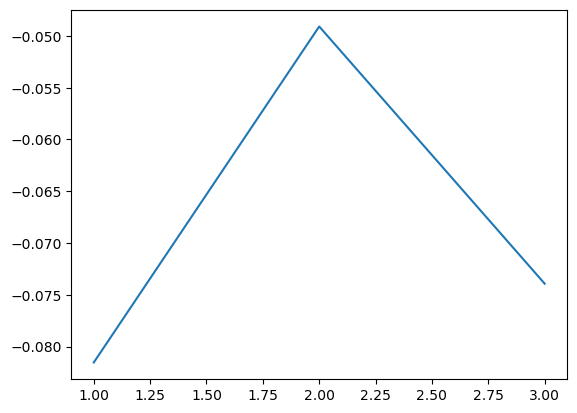

In [24]:
import matplotlib.pyplot as plt

plt.plot(X,Y_log)
plt.show()

In [25]:
from sklearn.model_selection import cross_val_score

cross_val_score(sgd_clf, # Model of classifier
                X_train, 
                y_train_5, 
                cv = 3, scoring="accuracy")

array([0.94505, 0.96655, 0.95005])

In [26]:
from sklearn.base import BaseEstimator

class Never5Classigier(BaseEstimator):
    def fit(self, X, y = None):
        pass
    def predict(self, X):
        return np.zeros((len(X), 1), dtype = bool)

In [27]:
never_5_clf = Never5Classigier()

In [28]:
cross_val_score(never_5_clf, X_train, y_train_5, cv=3, scoring='accuracy')

array([0.9088 , 0.91065, 0.9095 ])

In [29]:
from sklearn.model_selection import cross_val_predict
y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3)

In [30]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_train_5, y_train_pred)

array([[52672,  1907],
       [  860,  4561]])

- `53419`: Negative(Actual result is non-5s) + False(predict that is non-5 digits)
- `1160`: Negative + True
- `1302`: Positive + False
- `4119`: Positive + True

In [31]:
from sklearn.metrics import recall_score, f1_score, precision_score

In [32]:
precision_score(y_train_5, y_train_pred)

0.7051638837353124

In [33]:
f1_score(y_train_5, y_train_pred)

0.7672638573471275

In [34]:
recall_score(y_train_5, y_train_pred)

0.8413576830843018

In [35]:
BaseEstimator

sklearn.base.BaseEstimator

In [36]:
y_train_5

55145    False
6217      True
15533    False
50078    False
8318     False
         ...  
44293     True
17351    False
18056    False
31171    False
32215    False
Name: class, Length: 60000, dtype: bool

In [37]:
y_scores = cross_val_predict(sgd_clf, X_train, y_train_5, cv = 3, method="decision_function")

In [38]:
y_scores

array([  1015.47011858,  23696.11729844,  -2622.22987262, ...,
        -6724.964749  , -27244.47410638, -11685.04678551], shape=(60000,))

In [39]:
threshold = 0
y_some_digit_pred = (y_scores > threshold)

In [40]:
threshold = 200000
y_some_digit_pred = (y_scores > threshold)
y_some_digit_pred

array([False, False, False, ..., False, False, False], shape=(60000,))

In [41]:
from sklearn.metrics import precision_recall_curve
precisions, recalls, thresholds = precision_recall_curve(y_train_5, y_scores)

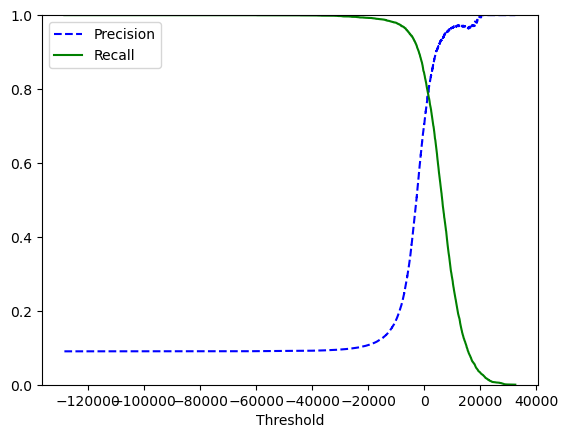

In [42]:
def plot_precision_recall_vs_threshold(precision, recalls, thresholds): 
    plt.plot(thresholds, precisions[:-1], '--b', label = "Precision")
    plt.plot(thresholds, recalls[:-1], "g-", label ="Recall")
    plt.xlabel("Threshold")
    plt.legend(loc = "upper left")
    plt.ylim([0,1])

plot_precision_recall_vs_threshold(precisions, recalls, thresholds)

Text(0, 0.5, 'Precision')

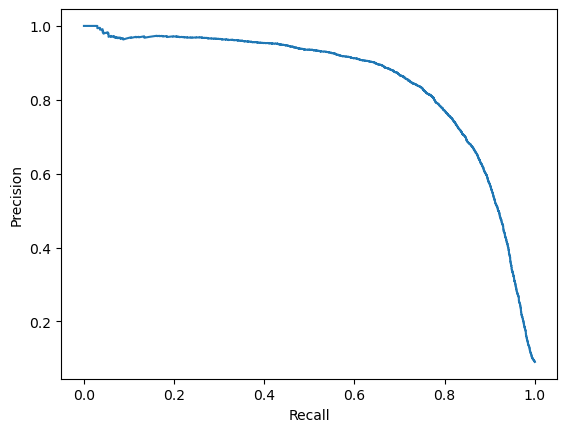

In [43]:
plt.plot(recalls, precisions)
plt.xlabel("Recall")
plt.ylabel("Precision")

In [44]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_train_5, y_scores)

In [45]:
def plot_roc_curve(fpr, tpr, label = None):
    plt.plot(fpr, tpr, label = label)
    plt.plot([0, 1], [0, 1], 'k--')
    plt.axis([0,1, 0, 1])
    plt.xlabel("Faslse Positive Rate")
    plt.ylabel("True Positive Rate")

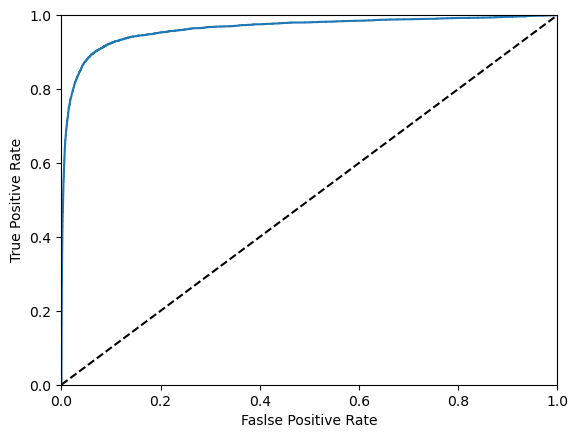

In [46]:
plot_roc_curve(fpr, tpr) 
plt.show()

In [47]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_train_5, y_scores)

0.9634365426659639

In [48]:
from sklearn.ensemble import RandomForestClassifier
forest_clf = RandomForestClassifier(random_state=42)
y_probas_forest = cross_val_predict(forest_clf, X_train, y_train_5, cv = 3, 
                                 method = "predict_proba")

In [49]:
y_probas_forest

array([[0.79, 0.21],
       [0.08, 0.92],
       [0.99, 0.01],
       ...,
       [0.97, 0.03],
       [1.  , 0.  ],
       [1.  , 0.  ]], shape=(60000, 2))

In [50]:
y_score_forest = y_probas_forest[:, 1]
fpr_forest, tpr_forest, threshold_forest = roc_curve(y_train_5, y_score_forest)

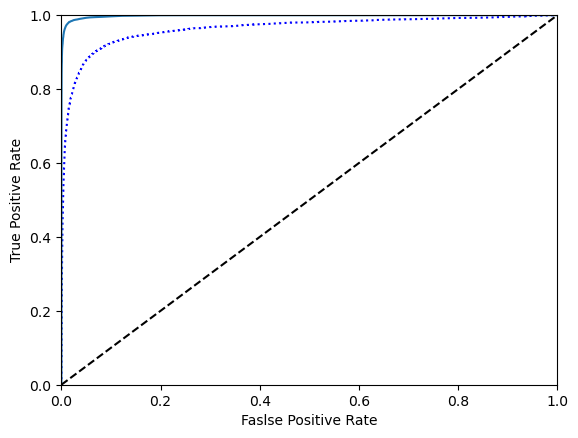

In [51]:
plt.plot(fpr, tpr, "b:", label ="SGD")
plot_roc_curve(fpr_forest, tpr_forest, "Random forest")

In [52]:
roc_auc_score(y_train_5, y_score_forest)

0.9983088946691439

In [53]:
sgd_clf.fit(X_train, y_train)

,loss,'hinge'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None


In [54]:
sgd_clf.predict([some_digit])

/home/znoy/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SGDClassifier was fitted with feature names
  warnings.warn(


array(['9'], dtype='<U1')

In [55]:
some_digit_score = sgd_clf.decision_function([some_digit])

/home/znoy/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SGDClassifier was fitted with feature names
  warnings.warn(


In [56]:
some_digit_score

array([[-42936.82235026, -27645.3786227 , -18522.05311898,
         -2243.14081055,  -4670.03412526,  -4027.69207761,
        -45026.56875594,  -7875.84378411,  -1398.71185897,
         -1389.33667309]])

In [57]:
np.argmax(some_digit_score)

np.int64(9)

In [58]:
sgd_clf.classes_

array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], dtype='<U1')

In [59]:
from sklearn.multiclass import OneVsOneClassifier

In [60]:
ovo_clf = OneVsOneClassifier(SGDClassifier(random_state=42))
ovo_clf.fit(X_train, y_train)
ovo_clf.predict([some_digit])

/home/znoy/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but OneVsOneClassifier was fitted with feature names
  warnings.warn(


array(['4'], dtype=object)

In [61]:
forest_clf.fit(X_train, y_train)
forest_clf.predict([some_digit])

/home/znoy/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


array(['9'], dtype=object)

In [62]:
forest_clf.predict_proba([some_digit])

/home/znoy/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


array([[0.  , 0.  , 0.  , 0.  , 0.03, 0.01, 0.  , 0.01, 0.  , 0.95]])

In [63]:
cross_val_score(sgd_clf, X_train, y_train, cv=3, scoring="accuracy")

array([0.87765, 0.85265, 0.89275])

In [64]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.astype(np.float64))

In [65]:
cross_val_score(sgd_clf, X_train_scaled, y_train, cv = 3, scoring="accuracy")

/home/znoy/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_stochastic_gradient.py:726: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


array([0.89665, 0.8965 , 0.9053 ])

In [66]:
y_train_pred = cross_val_predict(sgd_clf, X_train_scaled, y_train, cv=3)

/home/znoy/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_stochastic_gradient.py:726: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


In [67]:
conf_mx = confusion_matrix(y_train, y_train_pred)

In [68]:
conf_mx

array([[5595,    0,   10,    6,    8,   37,   33,    6,  227,    1],
       [   1, 6410,   39,   22,    3,   41,    5,   10,  196,   15],
       [  27,   27, 5221,   91,   69,   27,   70,   39,  378,    9],
       [  25,   20,  107, 5242,    1,  198,   25,   45,  404,   64],
       [  13,   13,   37,   13, 5210,    9,   35,   16,  338,  158],
       [  25,   17,   23,  161,   47, 4459,   85,   19,  523,   62],
       [  29,   15,   42,    3,   48,   88, 5547,    8,  138,    0],
       [  18,    9,   53,   27,   48,    9,    4, 5717,  171,  209],
       [  14,   63,   37,   97,    2,  121,   29,    9, 5433,   46],
       [  26,   20,   26,   57,  119,   33,    1,  175,  357, 5135]])

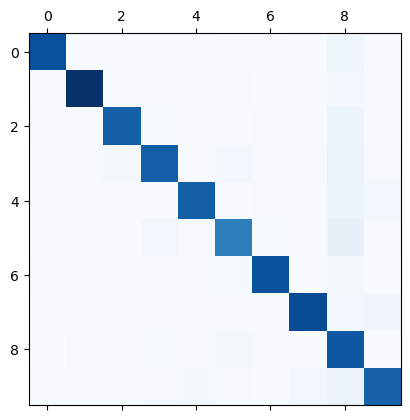

In [69]:
plt.matshow(conf_mx, cmap= plt.cm.Blues)
plt.show()

In [70]:
from sklearn.neighbors import KNeighborsClassifier
y_train_large = (y_train.astype(int) >= 7)
y_train_odd = (y_train.astype(int) % 2 == 1)
y_multilabel = np.c_[y_train_large, y_train_odd]

In [71]:
knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train, y_multilabel)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [72]:
knn_clf.predict([some_digit])

/home/znoy/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


array([[ True,  True]])

In [75]:
y_train_knn_pred = cross_val_predict(knn_clf, X_train, y_train, cv = 3)
f1_score(y_train, y_train_knn_pred, average="macro")

0.9689504495241256

In [81]:
import numpy.random as rnd
noise = rnd.randint(0, 100, (len(X_train), 784))
X_train_mod = X_train + noise

noise = rnd.randint(0, 100, (len(X_test), 784))
X_test_mod = X_test + noise

y_train_mod = X_train
y_test_mod = X_test



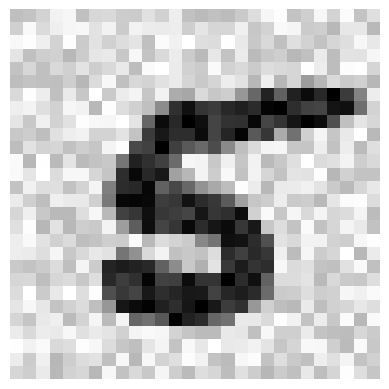

In [83]:
import matplotlib
import matplotlib.pyplot as plt
some_digit = X_train_mod.iloc[1]
some_digit_image = some_digit.values.reshape(28,28)
plt.imshow(some_digit_image, cmap=matplotlib.cm.binary,
          interpolation="nearest")
plt.axis("off")
plt.show()

In [85]:
knn_clf.fit(X_train_mod, y_train_mod)
clean_digit = knn_clf.predict([X_test_mod.iloc[1]])

/home/znoy/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [86]:
import matplotlib
import matplotlib.pyplot as plt
some_digit = clean_digit
some_digit_image = some_digit.values.reshape(28,28)
plt.imshow(some_digit_image, cmap=matplotlib.cm.binary,
          interpolation="nearest")
plt.axis("off")
plt.show()

AttributeError: 'numpy.ndarray' object has no attribute 'values'